# Option Pricing: Heston Stochastic Volatility Calibrated to SPY Options

## Problem
Black-Scholes assumes one constant volatility, but the implied volatility of SPY options varies with strike (the skew or smile) and with maturity. The Heston (1993) model lets variance follow a mean-reverting square-root process correlated with the asset, which can reproduce a skew. This notebook prices calls by Fourier inversion of the Heston characteristic function, calibrates the five Heston parameters to today's SPY mid prices, and compares the fit with Black-Scholes at implied volatility.

## Data
Source: Yahoo Finance via `yfinance`, read on the run date (2026-11-19). The data are the SPY spot, the SPY option chains (bid, ask, volume, open interest, last-trade time), and the 13-week Treasury bill (`^IRX`) used as the risk-free rate $r$.

Selection: three expiries between 30 and 120 calendar days out. Calibration calls are kept if bid > 0, ask > bid, traded volume $\ge 10$, $|K/S - 1| \le 5\%$ and the relative spread $(\text{ask}-\text{bid})/\text{mid} \le 20\%$. Mid price $= (\text{bid}+\text{ask})/2$. Put-call parity at each expiry (call and put mids at common strikes within $\pm 10\%$) gives the forward $F$, and the dividend yield $q$ is then set so that $Se^{(r-q)T} = F$.

A status check at the top of the notebook states whether the regular session is open at run time and how old the option last trades are. If the market is closed, the quotes are stale and that is stated in the Results.

## Method
Under the risk-neutral measure, the spot and variance follow

$$dS_t = (r-q)S_t\,dt + \sqrt{v_t}\,S_t\,dW^1_t, \qquad dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dW^2_t, \qquad d\langle W^1, W^2\rangle_t = \rho\,dt$$

with parameters $\kappa$ (mean reversion), $\theta$ (long-run variance), $\xi$ (vol of vol), $\rho$ (spot-variance correlation) and $v_0$ (initial variance).

**Pricing (Gil-Pelaez / Heston inversion).** With $\varphi(u) = E[e^{iu\ln S_T}]$ and $F = S e^{(r-q)T}$, the call price is

$$C = S e^{-qT} P_1 - K e^{-rT} P_2, \qquad P_j = \tfrac12 + \frac{1}{\pi}\int_0^\infty \mathrm{Re}\!\left[\frac{e^{-iu\ln K}\,\varphi_j(u)}{iu}\right]du$$

where $\varphi_2(u) = \varphi(u)$ and $\varphi_1(u) = \varphi(u-i)/\varphi(-i) = \varphi(u-i)/F$. The characteristic function uses the "little trap" form of Albrecher et al. (2007), which avoids branch-cut discontinuities of the complex logarithm. With $b = \kappa - \rho\xi iu$ and $d = \sqrt{b^2 + \xi^2(iu + u^2)}$:

$$g = \frac{b-d}{b+d}, \qquad \varphi(u) = \exp\!\Big(C(u,T) + D(u,T)v_0 + iu\ln S\Big)$$

$$C = (r-q)iuT + \frac{\kappa\theta}{\xi^2}\Big[(b-d)T - 2\ln\frac{1-ge^{-dT}}{1-g}\Big], \qquad D = \frac{b-d}{\xi^2}\,\frac{1-e^{-dT}}{1-ge^{-dT}}$$

The integrals are evaluated with `scipy.integrate.quad` on $[0, 400]$.

**Calibration.** The five parameters minimise the squared price errors against the mid prices, subject to bounds ($\kappa \in [0.01, 20]$, $\theta \in [10^{-3}, 1]$, $\xi \in [0.01, 5]$, $\rho \in [-0.99, 0.99]$, $v_0 \in [10^{-3}, 1]$). The solver is `scipy.optimize.least_squares` (trust-region reflective) from two starting points, and the best fit is kept. The Feller quantity $2\kappa\theta - \xi^2$ is reported but not imposed.

**Benchmark.** Black-Scholes implied volatility $\sigma_{\rm imp}$ is obtained by root-finding on the mid price (`brentq`). A flat Black-Scholes benchmark uses the ATM implied vol of each expiry for every strike. The model's implied-vol smile is computed by inverting the Heston prices the same way.

In [1]:
import datetime as dt
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.integrate import quad
from scipy.optimize import least_squares, brentq
from scipy.stats import norm

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.grid': True})

NY = 'America/New_York'
now = pd.Timestamp.now(tz=NY)
today = pd.Timestamp(now.date())
minutes = now.hour * 60 + now.minute
market_open = (now.weekday() < 5) and (9 * 60 + 30 <= minutes < 16 * 60)

spy = yf.Ticker('SPY')
spot = float(spy.fast_info['lastPrice'])
spot_prev = float(spy.fast_info['previousClose'])
r = float(yf.Ticker('^IRX').history(period='10d')['Close'].dropna().iloc[-1]) / 100.0

print(f"Run time (New York): {now:%Y-%m-%d %H:%M %Z}; regular session open: {market_open}")
print(f"SPY spot {spot:.2f} (previous close {spot_prev:.2f}); 13-week T-bill r = {r:.4%}")

def years_to_expiry(exp_str):
    exp_ts = pd.Timestamp(exp_str + ' 16:00', tz=NY)
    return (exp_ts - now).total_seconds() / (365.0 * 24 * 3600)

cands = []
for e in spy.options:
    d = (pd.Timestamp(e) - today).days
    if 30 <= d <= 120:
        cands.append((e, d))
print("Expiries 30 to 120 days out:", cands)
pick = sorted(set(np.linspace(0, len(cands) - 1, min(3, len(cands))).round().astype(int)))
expiries = [cands[i] for i in pick]
print("Selected expiries:", expiries)

Run time (New York): 2026-11-19 12:18 EST; regular session open: True
SPY spot 718.72 (previous close 733.50); 13-week T-bill r = 4.1530%
Expiries 30 to 120 days out: [('2026-12-24', 35), ('2026-12-31', 42), ('2027-01-15', 57), ('2027-01-29', 71), ('2027-02-19', 92), ('2027-02-26', 99), ('2027-03-19', 120)]
Selected expiries: [('2026-12-24', 35), ('2027-01-29', 71), ('2027-03-19', 120)]


In [2]:
MONEY_BAND = 0.10   # parity: |K/S - 1| <= 10%
CAL_BAND = 0.05     # calibration calls: |K/S - 1| <= 5%
MIN_VOL = 10        # minimum traded volume for calibration calls
MAX_REL_SPREAD = 0.20  # drop quotes with (ask - bid) / mid > 20%

chains, rows, parity = {}, [], []
for e, d in expiries:
    T = years_to_expiry(e)
    ch = spy.option_chain(e)
    chains[e] = ch
    calls, puts = ch.calls.copy(), ch.puts.copy()
    # Put-call parity to infer the forward and q (bid > 0, same moneyness band)
    c_ok = calls[(calls.bid > 0) & (calls.ask > calls.bid) & ((calls.strike / spot - 1).abs() <= MONEY_BAND)]
    p_ok = puts[(puts.bid > 0) & (puts.ask > puts.bid) & ((puts.strike / spot - 1).abs() <= MONEY_BAND)]
    m = c_ok[['strike', 'bid', 'ask']].merge(p_ok[['strike', 'bid', 'ask']], on='strike', suffixes=('_c', '_p'))
    c_mid = (m.bid_c + m.ask_c) / 2; p_mid = (m.bid_p + m.ask_p) / 2
    F_k = m.strike + np.exp(r * T) * (c_mid - p_mid)
    F = float(np.median(F_k)) if len(F_k) else spot * np.exp(r * T)
    q = r - np.log(F / spot) / T
    parity.append(dict(expiry=e, days=d, T=T, n_pairs=len(m), forward=F, q_implied=q))

    # Calibration calls
    n0 = len(calls)
    c = calls[(calls.bid > 0) & (calls.ask > calls.bid)]
    n1 = len(c)
    c = c[(c.strike / spot - 1).abs() <= CAL_BAND]
    n2 = len(c)
    c = c[c.volume.fillna(0) >= MIN_VOL]
    n3 = len(c)
    c = c[(c.ask - c.bid) / ((c.ask + c.bid) / 2) <= MAX_REL_SPREAD]
    n4 = len(c)
    age_min = ((now - pd.to_datetime(c.lastTradeDate, utc=True).dt.tz_convert(NY)).dt.total_seconds() / 60).median() if n4 else np.nan
    print(f"{e} ({d} days, T={T:.4f}): calls {n0} -> bid/ask ok {n1} -> |K/S-1|<=5% {n2} -> volume>={MIN_VOL} {n3} "
          f"-> spread<=20% {n4}; median last-trade age {age_min:.1f} min; parity q={q:.4%}, forward {F:.2f}")
    for _, row in c.iterrows():
        rows.append(dict(expiry=e, T=T, K=float(row.strike), bid=float(row.bid), ask=float(row.ask),
                         mid=float(0.5 * (row.bid + row.ask)), volume=float(row.volume),
                         open_interest=float(row.openInterest), lastTrade=row.lastTradeDate,
                         S=spot, r=r, q=q))

opts = pd.DataFrame(rows)
print(pd.DataFrame(parity).to_string(index=False, float_format=lambda v: f'{v:,.5f}'))
print(f"\nCalibration set: {len(opts)} calls across {opts.expiry.nunique()} expiries")
print(opts.groupby('expiry').agg(n=('K', 'size'), K_min=('K', 'min'), K_max=('K', 'max'),
                                  mid_median=('mid', 'median')).to_string(float_format=lambda v: f'{v:,.4f}'))

2026-12-24 (35 days, T=0.0963): calls 120 -> bid/ask ok 118 -> |K/S-1|<=5% 37 -> volume>=10 21 -> spread<=20% 21; median last-trade age 23.9 min; parity q=-1.2083%, forward 722.44
2027-01-29 (71 days, T=0.1949): calls 219 -> bid/ask ok 208 -> |K/S-1|<=5% 68 -> volume>=10 24 -> spread<=20% 24; median last-trade age 42.2 min; parity q=-0.4255%, forward 725.16


2027-03-19 (120 days, T=0.3291): calls 198 -> bid/ask ok 157 -> |K/S-1|<=5% 14 -> volume>=10 11 -> spread<=20% 11; median last-trade age 26.9 min; parity q=-0.0522%, forward 728.73
    expiry  days       T  n_pairs   forward  q_implied
2026-12-24    35 0.09631       74 722.44067   -0.01208
2027-01-29    71 0.19494      117 725.16347   -0.00425
2027-03-19   120 0.32907       29 728.73489   -0.00052

Calibration set: 56 calls across 3 expiries
             n    K_min    K_max  mid_median
expiry                                      
2026-12-24  21 725.0000 750.0000     11.9500
2027-01-29  24 691.0000 754.0000     18.1225
2027-03-19  11 690.0000 750.0000     35.6200


In [3]:
def heston_cf(u, T, S, r, q, kappa, theta, xi, rho, v0):
    """phi(u) = E[exp(i u ln S_T)] under Heston, little-trap formulation."""
    iu = 1j * u
    x = np.log(S)
    b = kappa - rho * xi * iu
    d = np.sqrt(b**2 + xi**2 * (iu + u**2))
    g = (b - d) / (b + d)
    edT = np.exp(-d * T)
    C = (r - q) * iu * T + kappa * theta / xi**2 * ((b - d) * T - 2 * np.log((1 - g * edT) / (1 - g)))
    D = (b - d) / xi**2 * (1 - edT) / (1 - g * edT)
    return np.exp(C + D * v0 + iu * x)

def heston_call(S, K, T, r, q, kappa, theta, xi, rho, v0, U=400.0):
    """European call price by Gil-Pelaez inversion of the Heston characteristic function."""
    lnK = np.log(K)
    F = S * np.exp((r - q) * T)
    def f1(u):
        val = np.exp(-1j * u * lnK) * heston_cf(u - 1j, T, S, r, q, kappa, theta, xi, rho, v0) / (1j * u * F)
        return val.real
    def f2(u):
        val = np.exp(-1j * u * lnK) * heston_cf(u, T, S, r, q, kappa, theta, xi, rho, v0) / (1j * u)
        return val.real
    I1 = quad(f1, 1e-10, U, limit=500)[0]
    I2 = quad(f2, 1e-10, U, limit=500)[0]
    P1 = 0.5 + I1 / np.pi
    P2 = 0.5 + I2 / np.pi
    return S * np.exp(-q * T) * P1 - K * np.exp(-r * T) * P2

def bs_call(S, K, T, r, q, sig):
    d1 = (np.log(S / K) + (r - q + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def implied_vol(price, S, K, T, r, q):
    intrinsic = max(S * np.exp(-q * T) - K * np.exp(-r * T), 0.0)
    if not np.isfinite(price) or price <= intrinsic + 1e-10:
        return np.nan
    try:
        return brentq(lambda s: bs_call(S, K, T, r, q, s) - price, 1e-4, 5.0, xtol=1e-12)
    except ValueError:
        return np.nan

# Verification 1: Heston with vanishing vol-of-vol collapses to Black-Scholes at sqrt(theta)=sqrt(v0)
S_, K_, T_, r_, q_ = 100.0, 105.0, 0.5, 0.03, 0.01
sig_bs = 0.20
h_price = heston_call(S_, K_, T_, r_, q_, kappa=2.0, theta=sig_bs**2, xi=1e-3, rho=0.0, v0=sig_bs**2)
bs_price = bs_call(S_, K_, T_, r_, q_, sig_bs)
print(f"Check 1 (xi -> 0): Heston {h_price:.6f} vs Black-Scholes {bs_price:.6f}, abs diff {abs(h_price - bs_price):.2e}")

# Verification 2: put-call parity on a Heston price with skew
hp = heston_call(S_, K_, T_, r_, q_, kappa=1.5, theta=0.05, xi=0.6, rho=-0.7, v0=0.04)
put = hp - S_ * np.exp(-q_ * T_) + K_ * np.exp(-r_ * T_)
print(f"Check 2 (put-call parity): call {hp:.6f}, implied put {put:.6f}, price sanity (0 < C < S): {0 < hp < S_}")

# Timing of one full price evaluation
t0 = time.time()
for _ in range(20):
    heston_call(S_, K_, T_, r_, q_, 1.5, 0.05, 0.6, -0.7, 0.04)
print(f"Average time per Heston price: {(time.time() - t0) / 20 * 1000:.1f} ms")

Check 1 (xi -> 0): Heston 3.965695 vs Black-Scholes 3.965696, abs diff 1.34e-06
Check 2 (put-call parity): call 3.112596, implied put 7.048101, price sanity (0 < C < S): True
Average time per Heston price: 3.7 ms


In [4]:
def model_prices(p, df):
    k, th, xi, rho, v0 = p
    return np.array([heston_call(row.S, row.K, row.T, row.r, row.q, k, th, xi, rho, v0)
                     for row in df.itertuples()])

def residuals(p, df):
    res = model_prices(p, df) - df.mid.values
    return np.nan_to_num(res, nan=1e3, posinf=1e3, neginf=-1e3)

LB = [0.01, 1e-3, 0.01, -0.99, 1e-3]
UB = [20.0, 1.0, 5.0, 0.99, 1.0]
STARTS = [(2.0, 0.04, 0.5, -0.7, 0.04), (1.0, 0.02, 0.3, -0.5, 0.03)]

fits = []
for x0 in STARTS:
    t0 = time.time()
    sol = least_squares(residuals, x0, args=(opts,), bounds=(LB, UB), x_scale='jac',
                        method='trf', max_nfev=60, ftol=1e-9, xtol=1e-9, gtol=1e-9)
    rmse = np.sqrt(np.mean(sol.fun**2))
    fits.append((rmse, sol))
    print(f"start {x0}: status {sol.status} ({sol.message}), nfev {sol.nfev}, "
          f"price RMSE {rmse:.4f} USD, {time.time() - t0:.0f} s")

best_rmse, best = min(fits, key=lambda z: z[0])
kappa, theta, xi, rho, v0 = best.x
print("\nBest Heston calibration:")
print(f"  kappa = {kappa:.4f}, theta = {theta:.5f} (sqrt {np.sqrt(theta):.4f}), xi = {xi:.4f}, "
      f"rho = {rho:.4f}, v0 = {v0:.5f} (sqrt {np.sqrt(v0):.4f})")
print(f"  Feller 2*kappa*theta - xi^2 = {2 * kappa * theta - xi**2:.5f} (positive means Feller condition holds)")
print(f"  price RMSE = {best_rmse:.4f} USD, max abs price error = {np.max(np.abs(best.fun)):.4f} USD")

start (2.0, 0.04, 0.5, -0.7, 0.04): status 2 (`ftol` termination condition is satisfied.), nfev 36, price RMSE 0.3665 USD, 143 s


start (1.0, 0.02, 0.3, -0.5, 0.03): status 2 (`ftol` termination condition is satisfied.), nfev 44, price RMSE 0.3665 USD, 119 s

Best Heston calibration:
  kappa = 14.1892, theta = 0.05355 (sqrt 0.2314), xi = 3.4070, rho = -0.6736, v0 = 0.09758 (sqrt 0.3124)
  Feller 2*kappa*theta - xi^2 = -10.08766 (positive means Feller condition holds)
  price RMSE = 0.3665 USD, max abs price error = 0.7468 USD


In [5]:
opts = opts.copy()
opts['heston_price'] = model_prices(best.x, opts)
opts['iv_mkt'] = [implied_vol(p, row.S, row.K, row.T, row.r, row.q) for p, row in zip(opts.mid, opts.itertuples())]
opts['iv_heston'] = [implied_vol(p, row.S, row.K, row.T, row.r, row.q) for p, row in zip(opts.heston_price, opts.itertuples())]
opts['iv_mkt_check'] = [bs_call(row.S, row.K, row.T, row.r, row.q, iv) if np.isfinite(iv) else np.nan
                        for iv, row in zip(opts.iv_mkt, opts.itertuples())]

# Flat Black-Scholes benchmark: ATM implied vol per expiry applied to all strikes
flat_rows = []
for e, grp in opts.groupby('expiry'):
    F = next(x['forward'] for x in parity if x['expiry'] == e)
    atm = grp.iloc[(grp.K - F).abs().argsort()].iloc[0]
    sig_atm = atm.iv_mkt
    flat_rows.append(pd.Series(bs_call(grp['S'], grp['K'], grp['T'], grp['r'], grp['q'], sig_atm), index=grp.index))
opts['bs_flat_price'] = pd.concat(flat_rows).reindex(opts.index)

def rmse(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return np.sqrt(np.mean((a[m] - b[m])**2)), int(m.sum())

rm_h, n_h = rmse(opts.heston_price.values, opts.mid.values)
rm_f, n_f = rmse(opts.bs_flat_price.values, opts.mid.values)
rm_iv, n_iv = rmse(opts.iv_heston.values, opts.iv_mkt.values)
rm_bs_check, _ = rmse(opts.iv_mkt_check.values, opts.mid.values)
print(f"Price RMSE (USD): Heston {rm_h:.4f} (n={n_h}) | flat Black-Scholes at ATM IV {rm_f:.4f} (n={n_f})")
print(f"Implied-vol RMSE (vol points): Heston vs market {100 * rm_iv:.3f} (n={n_iv})")
print(f"Check: Black-Scholes at each market implied vol reproduces the mid, max abs error "
      f"{np.nanmax(np.abs(opts.iv_mkt_check - opts.mid)):.2e} USD")
print()
print(opts[['expiry', 'K', 'mid', 'heston_price', 'bs_flat_price', 'iv_mkt', 'iv_heston']]
      .round(4).to_string(index=False))

Price RMSE (USD): Heston 0.3665 (n=56) | flat Black-Scholes at ATM IV 2.2351 (n=56)
Implied-vol RMSE (vol points): Heston vs market 0.339 (n=56)
Check: Black-Scholes at each market implied vol reproduces the mid, max abs error 2.96e-11 USD

    expiry     K    mid  heston_price  bs_flat_price  iv_mkt  iv_heston
2026-12-24 725.0 17.720       17.9899        17.7200  0.2126     0.2156
2026-12-24 726.0 16.870       17.3896        17.2605  0.2082     0.2140
2026-12-24 727.0 16.960       16.7993        16.8092  0.2143     0.2125
2026-12-24 728.0 16.515       16.2194        16.3662  0.2142     0.2109
2026-12-24 730.0 14.725       15.0916        15.5046  0.2037     0.2079
2026-12-24 731.0 14.940       14.5444        15.0860  0.2109     0.2064
2026-12-24 732.0 14.375       14.0086        14.6754  0.2091     0.2050
2026-12-24 733.0 12.985       13.4846        14.2729  0.1978     0.2036
2026-12-24 734.0 13.330       12.9726        13.8783  0.2063     0.2022
2026-12-24 735.0 12.885       12.4728  

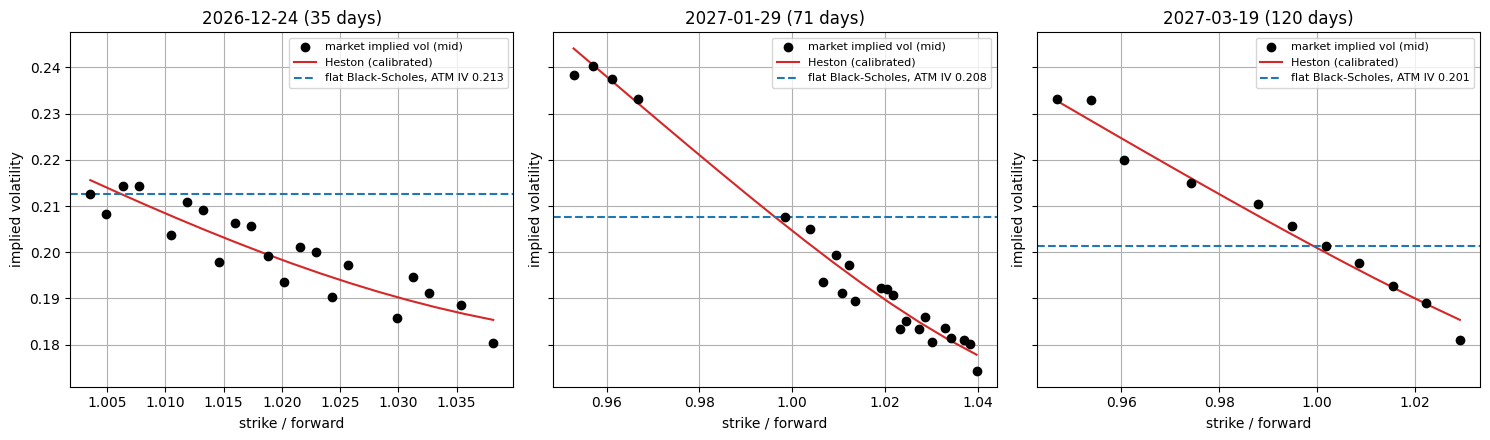

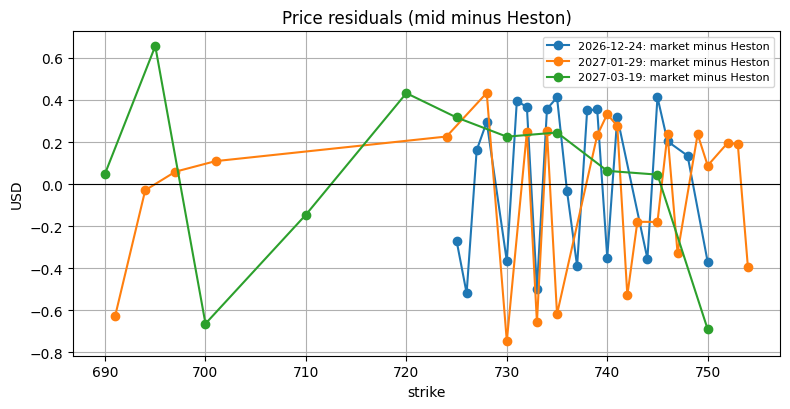

In [6]:
fig, axes = plt.subplots(1, len(expiries), figsize=(5 * len(expiries), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, (e, d) in zip(axes, expiries):
    grp = opts[opts.expiry == e].sort_values('K')
    F = next(x['forward'] for x in parity if x['expiry'] == e)
    T = grp['T'].iloc[0]
    kgrid = np.linspace(grp.K.min(), grp.K.max(), 15)
    iv_grid = [implied_vol(heston_call(spot, k, T, r, grp.q.iloc[0], *best.x), spot, k, T, r, grp.q.iloc[0]) for k in kgrid]
    ax.scatter(grp.K / F, grp.iv_mkt, c='k', zorder=3, label='market implied vol (mid)')
    ax.plot(kgrid / F, iv_grid, 'tab:red', label='Heston (calibrated)')
    atm_iv = grp.iloc[(grp.K - F).abs().argsort()].iloc[0].iv_mkt
    ax.axhline(atm_iv, color='tab:blue', ls='--', label=f'flat Black-Scholes, ATM IV {atm_iv:.3f}')
    ax.set_title(f'{e} ({d} days)')
    ax.set_xlabel('strike / forward')
    ax.set_ylabel('implied volatility')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
for e, grp in opts.groupby('expiry'):
    ax.plot(grp.K, grp.mid - grp.heston_price, 'o-', label=f'{e}: market minus Heston')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('strike'); ax.set_ylabel('USD'); ax.set_title('Price residuals (mid minus Heston)'); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Results
All numbers are from the executed cells above. The run was on 2026-11-19 at 12:18 New York time, during the regular session, so the quotes are live. Individual quotes are not all fresh, though: the median last-trade age is 24 min (Dec-24), 42 min (Jan-29) and 27 min (Mar-19).

- **Inputs.** SPY spot \$718.72 (previous close \$733.50). Risk-free rate $r = 4.153\%$ (13-week bill). Three expiries: 2026-12-24 (35 days), 2027-01-29 (71 days) and 2027-03-19 (120 days). The calibration set has 56 calls (21, 24 and 11 per expiry) with strikes from \$690 to \$754.
- **Forwards and q.** The parity forwards are 722.44, 725.16 and 728.73, all above the spot quote. The implied $q$ values are -1.21%, -0.43% and -0.05%. These are not dividend estimates. They absorb the gap between the spot quote and the option quotes, which are not taken at the same instant.
- **Pricer checks.** With $\xi \to 0$ the Heston price is 3.965695 against Black-Scholes 3.965696 (difference 1.3e-6). Put-call parity holds. One price takes 3.7 ms.
- **Calibrated parameters.** $\kappa = 14.19$, $\theta = 0.0536$ (long-run vol 23.1%), $\xi = 3.41$, $\rho = -0.674$, $v_0 = 0.0976$ (initial vol 31.2%). The Feller quantity $2\kappa\theta - \xi^2 = -10.09$ is negative, so the Feller condition is violated. It was not imposed.
- **Fit.** The solver stopped on the ftol condition after 36 and 44 evaluations. Both starts reached the same price RMSE, 0.3665 USD. The maximum absolute price error is 0.747 USD.
- **Heston against Black-Scholes.** Heston price RMSE is 0.367 USD (n = 56). The flat Black-Scholes benchmark at ATM implied vol gives 2.235 USD on the same quotes. Heston implied-vol RMSE against the market is 0.339 vol points.
- **Smile.** Market implied vol is 0.18 to 0.21 for Dec-24, 0.17 to 0.24 for Jan-29 and 0.18 to 0.23 for Mar-19. It slopes down with strike, and the calibrated Heston curve follows that slope.
- **Caveats.** The calibration uses 56 quotes to fit 5 parameters, so $\kappa$, $\xi$ and $v_0$ trade off against each other and are weakly identified. Treat the parameter values as a fit to one snapshot, not as stable estimates. The first attempt used a $\pm 10\%$ moneyness band and no spread filter. It did not fit: RMSE 3.15 USD, dominated by one wide-quoted 655 strike with a 61% implied vol, and $\xi$ ran into its upper bound of 3.0. The filters were then tightened as described in the Data section, and the bound on $\xi$ was raised to 5.0.

## Conclusions
1. **Heston reproduces the SPY smile much better than a flat Black-Scholes.** Calibrated to 56 call quotes at three expiries (35, 71 and 120 days), the price error is 0.37 USD (0.34 volatility points) against 2.24 USD for Black-Scholes with one at-the-money volatility. The model bends the implied-volatility curve in the right direction: lower implied volatility at higher strikes, as in the market quotes.
2. **The pricer is correct.** With the volatility of variance set near zero, Heston matches Black-Scholes to 1.3e-6, and put-call parity holds. These checks matter more than the fit, since a calibrated wrong pricer would also fit.
3. **The calibrated parameters should not be over-interpreted.** The fit gives mean reversion kappa 14.2, long-run volatility 23.1%, volatility of variance 3.41, correlation -0.67 and initial volatility 31.2%. The Feller condition is violated (2*kappa*theta - xi^2 = -10.09), so variance can touch zero in the model, and 56 quotes for 5 parameters leave them weakly identified. The sign of the correlation (negative: prices and volatility move in opposite directions) is the economically meaningful result.
4. **Data quality limits the conclusions.** The quotes were taken at 12:18 New York time with the market open, with median last-trade ages of 24 to 42 minutes, so some prices are stale; the first attempt with wider strikes and no spread filter did not fit (price error 3.15 USD, one wide-quoted strike dominated), and the version shown uses tighter filters. The fit used only two starting points and at most 60 evaluations. The parity-implied dividend yield came out negative because spot and option quotes are not synchronised, so it should not be read as a dividend estimate.
5. **A calibrated model is not a trading signal.** Fitting today's prices says nothing about whether options are mispriced; testing that would need out-of-sample prices on later days and transaction costs.

**Takeaway for the interview:** stochastic volatility with a negative correlation explains the equity skew that Black-Scholes cannot; but calibration is an ill-posed inverse problem, so validate the pricer first, filter the quotes, and check parameter plausibility (Feller, stability) rather than trusting the fit.